<a href="https://colab.research.google.com/github/iqbaal24/ML2026/blob/main/jobsheet_244107020105_MOHAMMAD_IQBAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PRAKTIKUM 1**

In [1]:
from google.colab import files

uploaded = files.upload()

Saving Iris.csv to Iris.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


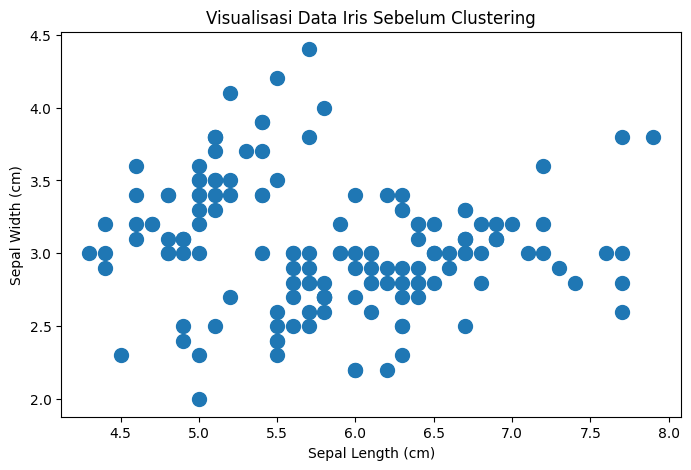

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Visualisasi Data Iris Sebelum Clustering')
plt.show()

In [5]:
cl_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

y_kmeans = cl_kmeans.fit_predict(X)

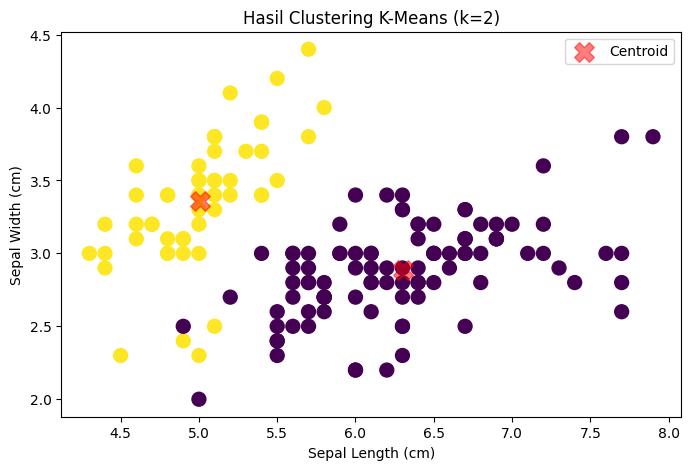

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    s=100,
    c=y_kmeans,
    cmap='viridis'
)

centers = cl_kmeans.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    s=200,
    alpha=0.5,
    marker='X',
    label='Centroid'
)

plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Hasil Clustering K-Means (k=2)')
plt.legend()
plt.show()

In [7]:
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


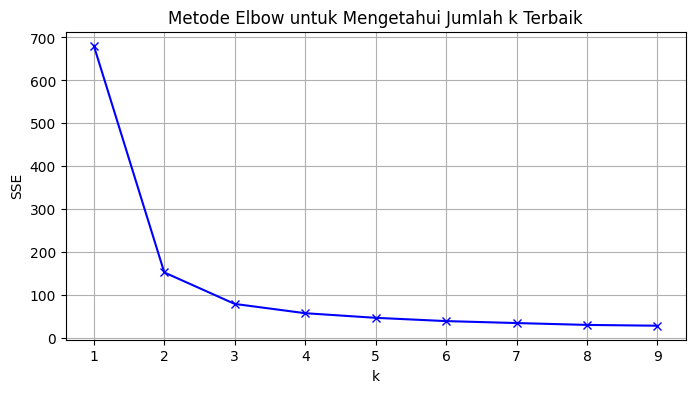

In [8]:
sse = []
K = range(1, 10)

for k in K:
    kmeanModel = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Metode Elbow untuk Mengetahui Jumlah k Terbaik')
plt.xticks(K)
plt.grid(True)
plt.show()

In [9]:
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8243999999996
k=2; SSE=152.36870647733915
k=3; SSE=78.94084142614601
k=4; SSE=57.317873214285726
k=5; SSE=46.535582051282034
k=6; SSE=38.930963049671746
k=7; SSE=34.36020891600983
k=8; SSE=30.02341635819898
k=9; SSE=28.145502489617765


**PRAKTIKUM 2**

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
import numpy as np

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

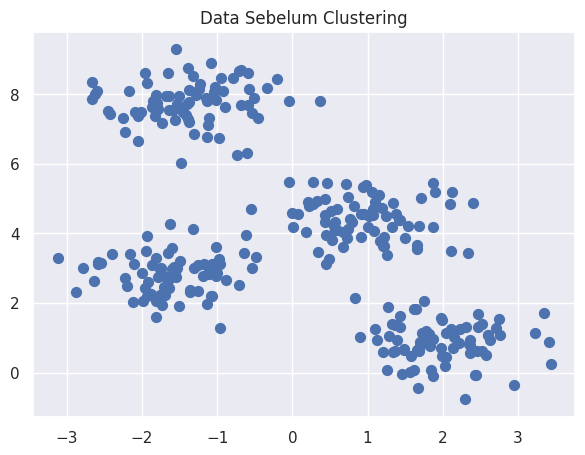

In [11]:
X, y_true = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=0.60,
    random_state=0
)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title('Data Sebelum Clustering')
plt.show()

In [13]:
kmeans = KMeans(
    n_clusters=4,
    random_state=0,
    n_init=10
)

kmeans.fit(X)
y_kmeans = kmeans.predict(X)

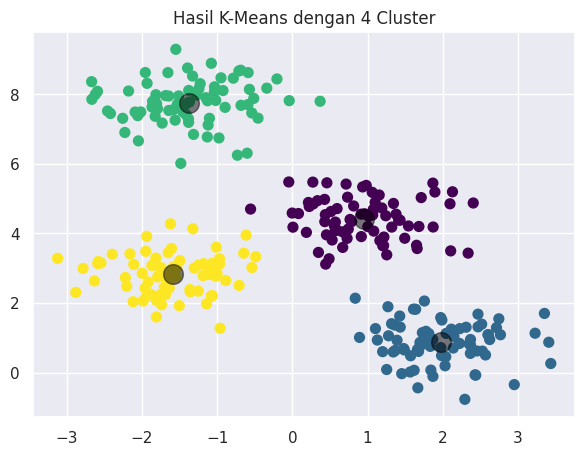

In [14]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0], X[:, 1],
    c=y_kmeans,
    s=50,
    cmap='viridis'
)

centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='black',
    s=200,
    alpha=0.5
)

plt.title('Hasil K-Means dengan 4 Cluster')
plt.show()

In [15]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]

    while True:
        # Menentukan cluster berdasarkan centroid terdekat
        labels = pairwise_distances_argmin(X, centers)

        # Menghitung centroid baru
        new_centers = np.array([
            X[labels == i].mean(0)
            for i in range(n_clusters)
        ])

        # Berhenti jika centroid sudah stabil
        if np.allclose(centers, new_centers):
            break

        centers = new_centers

    return centers, labels

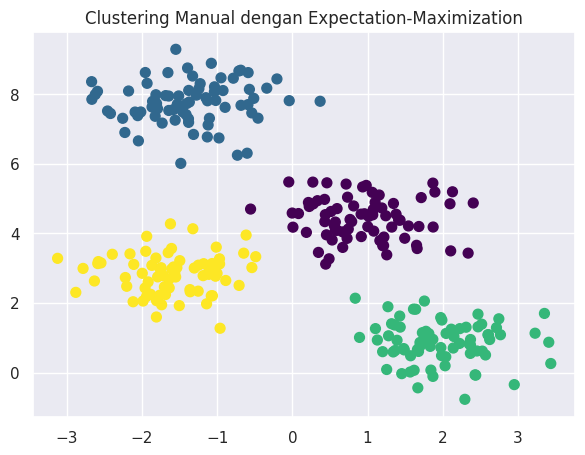

In [16]:
centers, labels = find_clusters(X, 4)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.title('Clustering Manual dengan Expectation-Maximization')
plt.show()

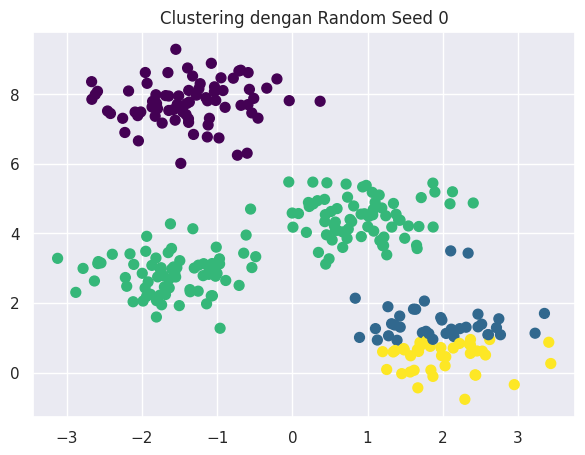

In [17]:
centers, labels = find_clusters(X, 4, rseed=0)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.title('Clustering dengan Random Seed 0')
plt.show()

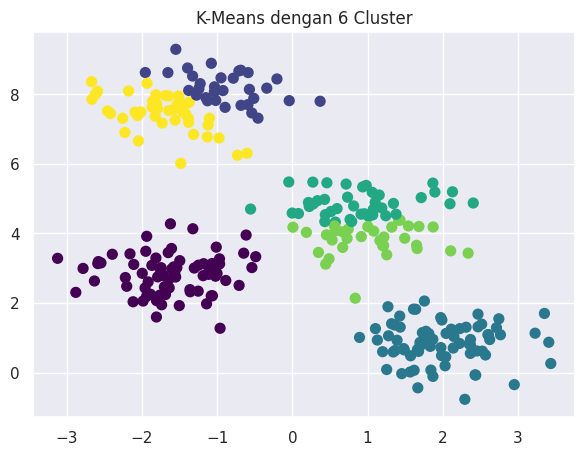

In [18]:
labels = KMeans(
    n_clusters=6,
    random_state=0,
    n_init=10
).fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.title('K-Means dengan 6 Cluster')
plt.show()

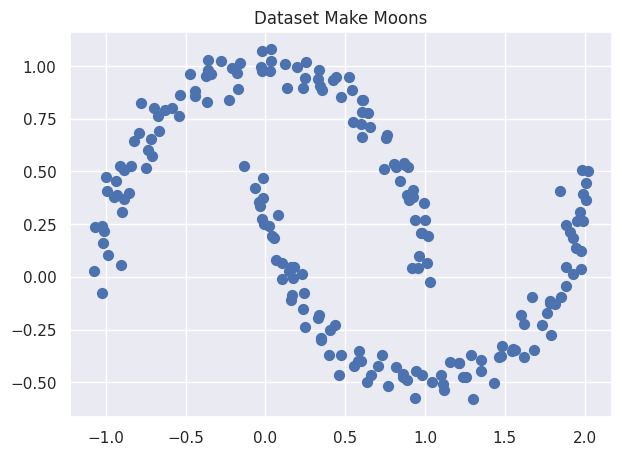

In [19]:
from sklearn.datasets import make_moons

X, y = make_moons(
    n_samples=200,
    noise=0.05,
    random_state=0
)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title('Dataset Make Moons')
plt.show()

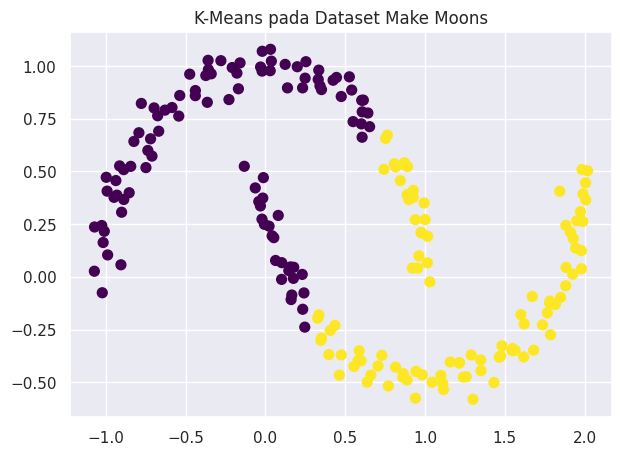

In [20]:
labels = KMeans(
    n_clusters=2,
    random_state=0,
    n_init=10
).fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.title('K-Means pada Dataset Make Moons')
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


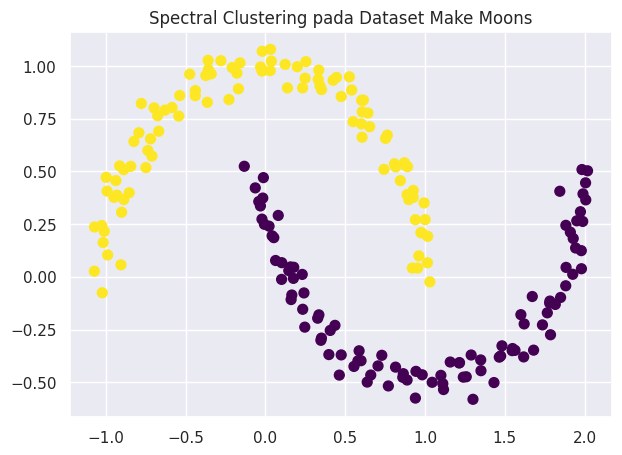

In [21]:
from sklearn.cluster import SpectralClustering

model = SpectralClustering(
    n_clusters=2,
    affinity='nearest_neighbors',
    assign_labels='kmeans',
    random_state=0
)

labels = model.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.title('Spectral Clustering pada Dataset Make Moons')
plt.show()

Studi Kasus 1: Clustering Karakter Angka

In [22]:
from sklearn.datasets import load_digits

digits = load_digits()

print("Bentuk dataset:", digits.data.shape)

Bentuk dataset: (1797, 64)


In [23]:
kmeans = KMeans(
    n_clusters=10,
    random_state=0,
    n_init=10
)

clusters = kmeans.fit_predict(digits.data)

print("Bentuk centroid:", kmeans.cluster_centers_.shape)

Bentuk centroid: (10, 64)


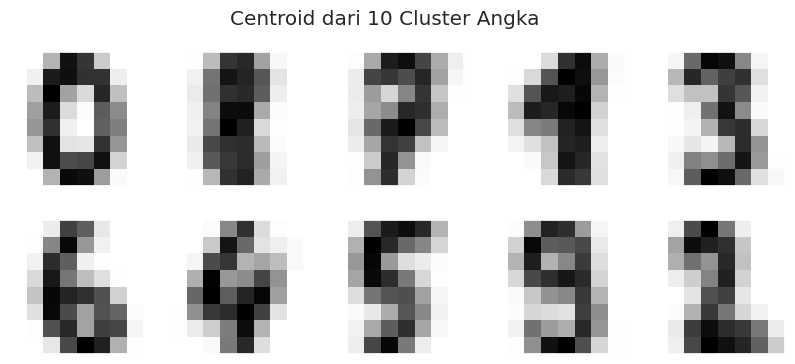

In [24]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4))

centers = kmeans.cluster_centers_.reshape(10, 8, 8)

for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

plt.suptitle('Centroid dari 10 Cluster Angka')
plt.show()

In [25]:
from scipy.stats import mode
from sklearn.metrics import accuracy_score

labels = np.zeros_like(clusters)

for i in range(10):
    mask = (clusters == i)

    if np.any(mask):
        labels[mask] = mode(
            digits.target[mask],
            keepdims=False
        ).mode

print("Akurasi:", accuracy_score(digits.target, labels))

Akurasi: 0.7918753478018921


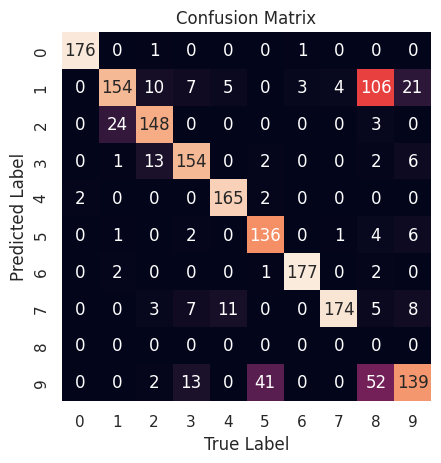

In [26]:
from sklearn.metrics import confusion_matrix

mat = confusion_matrix(
    digits.target,
    labels,
    labels=np.arange(10)
)

sns.heatmap(
    mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=digits.target_names,
    yticklabels=digits.target_names
)

plt.xlabel('True Label')
plt.ylabel('Predicted Label')
plt.title('Confusion Matrix')
plt.show()

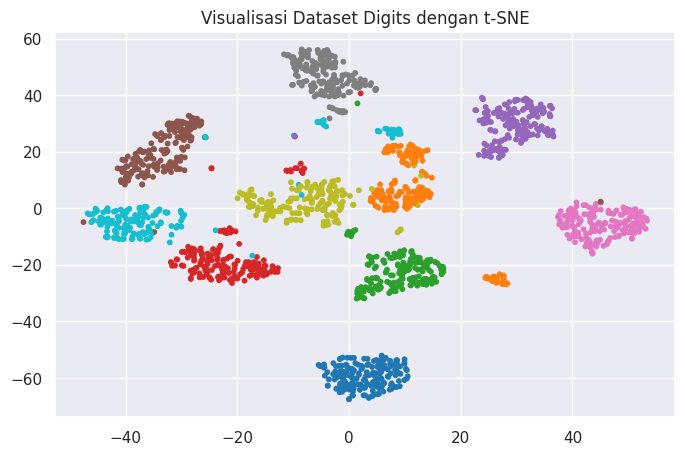

In [27]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    init='random',
    random_state=0
)

digits_proj = tsne.fit_transform(digits.data)

plt.figure(figsize=(8, 5))
plt.scatter(
    digits_proj[:, 0],
    digits_proj[:, 1],
    c=digits.target,
    cmap='tab10',
    s=10
)

plt.title('Visualisasi Dataset Digits dengan t-SNE')
plt.show()

In [28]:
kmeans = KMeans(
    n_clusters=10,
    random_state=0,
    n_init=10
)

clusters = kmeans.fit_predict(digits_proj)

labels = np.zeros_like(clusters)

for i in range(10):
    mask = clusters == i

    if np.any(mask):
        labels[mask] = mode(
            digits.target[mask],
            keepdims=False
        ).mode

print(
    "Akurasi setelah t-SNE:",
    accuracy_score(digits.target, labels)
)

Akurasi setelah t-SNE: 0.9410127991096272


Studi Kasus 2: Kompresi Citra

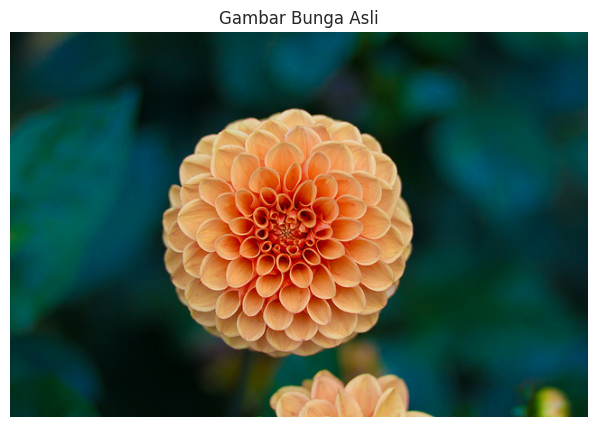

Ukuran gambar: (427, 640, 3)


In [29]:
from sklearn.datasets import load_sample_image

flower = load_sample_image("flower.jpg")

plt.figure(figsize=(8, 5))
plt.imshow(flower)
plt.axis('off')
plt.title('Gambar Bunga Asli')
plt.show()

print("Ukuran gambar:", flower.shape)

In [30]:
data = flower / 255.0
data = data.reshape(427 * 640, 3)

print("Bentuk data piksel:", data.shape)

Bentuk data piksel: (273280, 3)


In [31]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]

    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(
        xlabel='Red',
        ylabel='Green',
        xlim=(0, 1),
        ylim=(0, 1)
    )

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(
        xlabel='Red',
        ylabel='Blue',
        xlim=(0, 1),
        ylim=(0, 1)
    )

    fig.suptitle(title)
    plt.show()

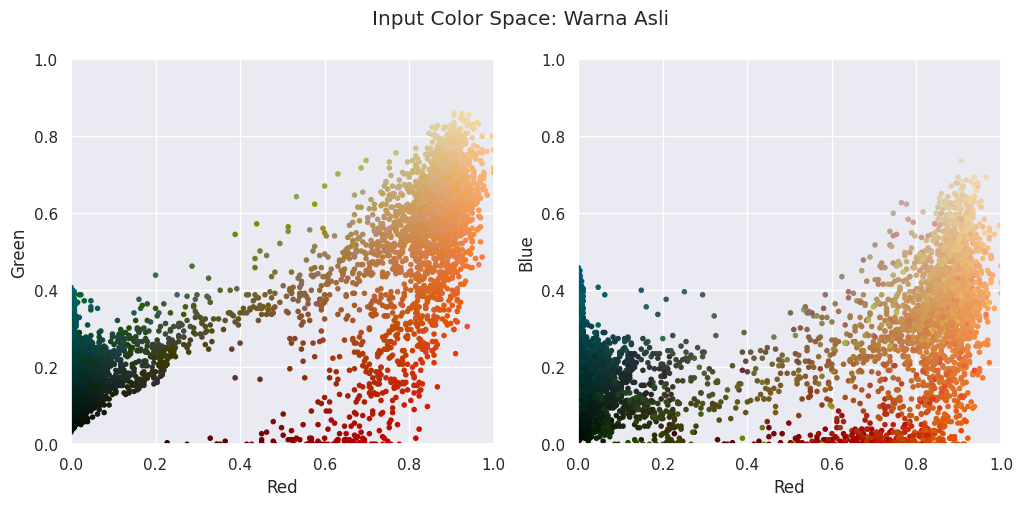

In [32]:
plot_pixels(
    data,
    title='Input Color Space: Warna Asli'
)

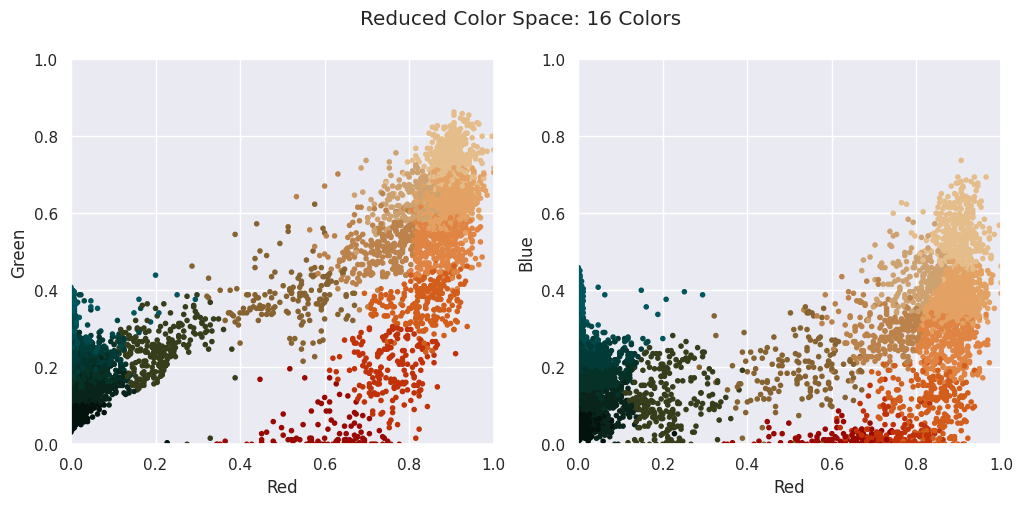

In [33]:
import warnings
warnings.simplefilter('ignore')

from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(
    n_clusters=16,
    random_state=0,
    n_init=3
)

kmeans.fit(data)

new_colors = kmeans.cluster_centers_[
    kmeans.predict(data)
]

plot_pixels(
    data,
    colors=new_colors,
    title='Reduced Color Space: 16 Colors'
)

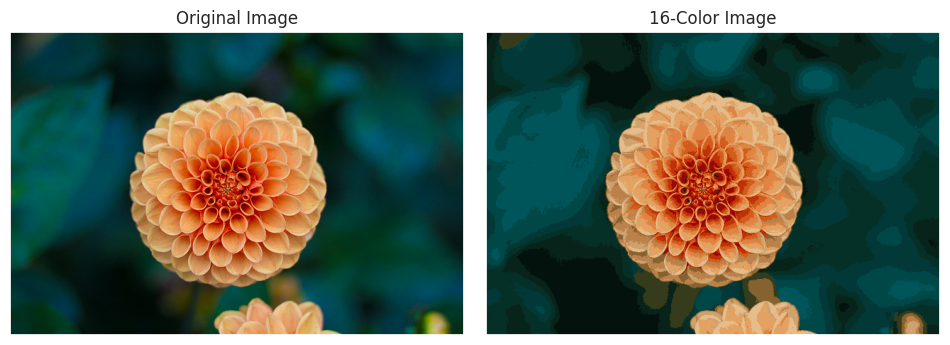

In [34]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(
    1, 2,
    figsize=(12, 5),
    subplot_kw=dict(xticks=[], yticks=[])
)

fig.subplots_adjust(wspace=0.05)

ax[0].imshow(flower)
ax[0].set_title('Original Image')

ax[1].imshow(np.clip(flower_recolored, 0, 1))
ax[1].set_title('16-Color Image')

plt.show()

**PRAKTIKUM 3**

In [35]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

centers = [[1, 1], [-1, -1], [1, -1]]

X, labels_true = make_blobs(
    n_samples=750,
    centers=centers,
    cluster_std=0.4,
    random_state=0
)

X = StandardScaler().fit_transform(X)

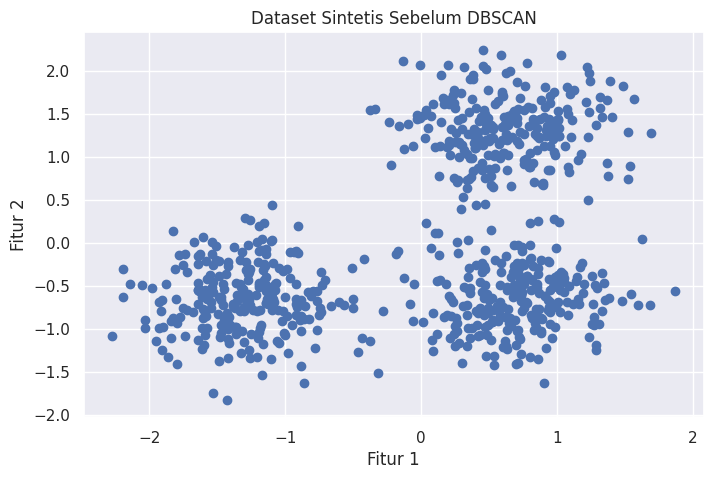

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1])
plt.title('Dataset Sintetis Sebelum DBSCAN')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.show()

In [37]:
import numpy as np
from sklearn.cluster import DBSCAN

db = DBSCAN(
    eps=0.3,
    min_samples=10
).fit(X)

labels = db.labels_

# Menghitung jumlah cluster tanpa noise
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)

# Menghitung jumlah titik noise
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 18


In [38]:
from sklearn import metrics

print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}")

# Silhouette memerlukan minimal 2 cluster dan tidak boleh semua titik satu cluster
if 1 < n_clusters_ < len(X):
    print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")
else:
    print("Silhouette Coefficient tidak dapat dihitung untuk jumlah cluster ini.")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


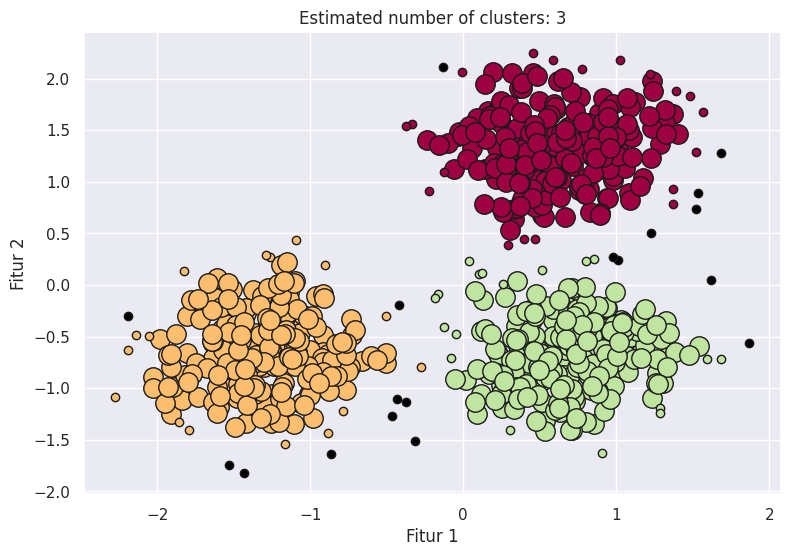

In [39]:
unique_labels = set(labels)

# Menandai core samples
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

# Membuat warna untuk setiap cluster
colors = [
    plt.cm.Spectral(each)
    for each in np.linspace(0, 1, len(unique_labels))
]

plt.figure(figsize=(9, 6))

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Warna hitam untuk noise
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    # Core samples: titik besar
    xy = X[class_member_mask & core_samples_mask]

    plt.plot(
        xy[:, 0],
        xy[:, 1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=14
    )

    # Non-core samples: titik kecil
    xy = X[class_member_mask & ~core_samples_mask]

    plt.plot(
        xy[:, 0],
        xy[:, 1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=6
    )

plt.title(f'Estimated number of clusters: {n_clusters_}')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.show()